In [1]:
from typing import List,Tuple
import os

import numpy as np
import pandas as pd
import kagglehub
import matplotlib.pyplot as plt
import seaborn as sns

from constants import RANDOM_STATE, PLOTS_PATH, DATASET_HANDLE

/home/alexandre/projects/mestrado-aulas/mineracao-de-dados/trabalho/projeto/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
path = kagglehub.competition_download(DATASET_HANDLE)
print("Path to competition files:", path)

Path to competition files: /home/alexandre/.cache/kagglehub/competitions/alzheimers-disease-risk-prediction-eu-business


In [3]:
print("Competition data Directory files: ")
for file in os.listdir(path):
    print(file, "; path=", os.path.join(path,file))

Competition data Directory files: 
train.csv ; path= /home/alexandre/.cache/kagglehub/competitions/alzheimers-disease-risk-prediction-eu-business/train.csv
submission_template.csv ; path= /home/alexandre/.cache/kagglehub/competitions/alzheimers-disease-risk-prediction-eu-business/submission_template.csv
test.csv ; path= /home/alexandre/.cache/kagglehub/competitions/alzheimers-disease-risk-prediction-eu-business/test.csv
data_description.txt ; path= /home/alexandre/.cache/kagglehub/competitions/alzheimers-disease-risk-prediction-eu-business/data_description.txt


In [4]:
df = pd.read_csv(os.path.join(path,"train.csv"))

In [8]:
print("Amount of rows: ", len(df))
print("Amount of columns: ", len(df.columns))
print("Columns: ", df.columns)

Amount of rows:  1719
Amount of columns:  35
Columns:  Index(['PatientID', 'Age', 'Gender', 'Ethnicity', 'EducationLevel', 'BMI',
       'Smoking', 'AlcoholConsumption', 'PhysicalActivity', 'DietQuality',
       'SleepQuality', 'FamilyHistoryAlzheimers', 'CardiovascularDisease',
       'Diabetes', 'Depression', 'HeadInjury', 'Hypertension', 'SystolicBP',
       'DiastolicBP', 'CholesterolTotal', 'CholesterolLDL', 'CholesterolHDL',
       'CholesterolTriglycerides', 'MMSE', 'FunctionalAssessment',
       'MemoryComplaints', 'BehavioralProblems', 'ADL', 'Confusion',
       'Disorientation', 'PersonalityChanges', 'DifficultyCompletingTasks',
       'Forgetfulness', 'Diagnosis', 'DoctorInCharge'],
      dtype='str')


In [9]:
print("Age range: ", df.Age.min(), "-", df.Age.max())

Age range:  60 - 90


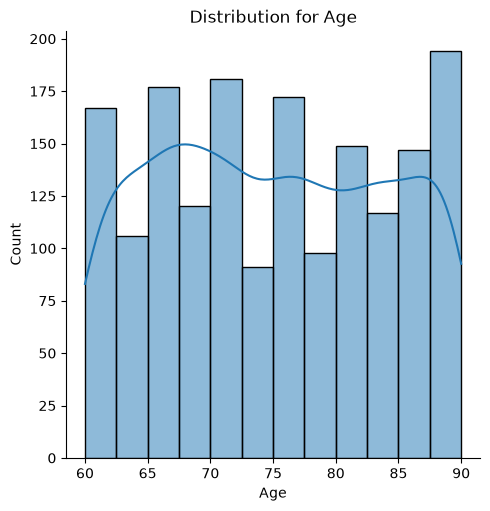

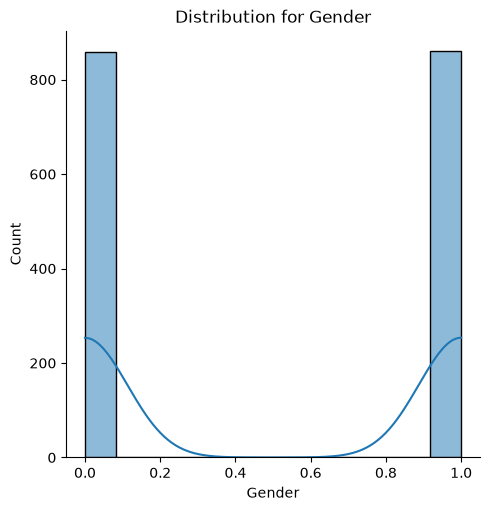

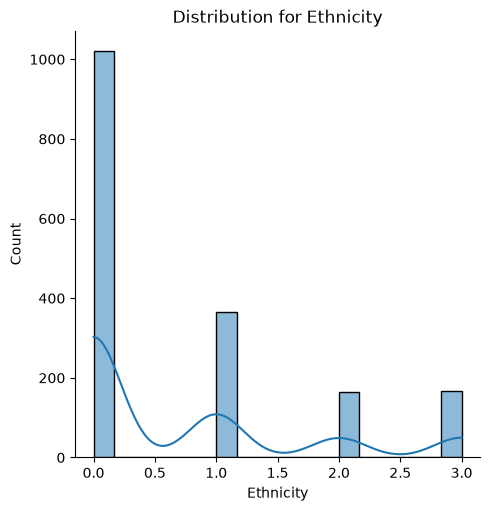

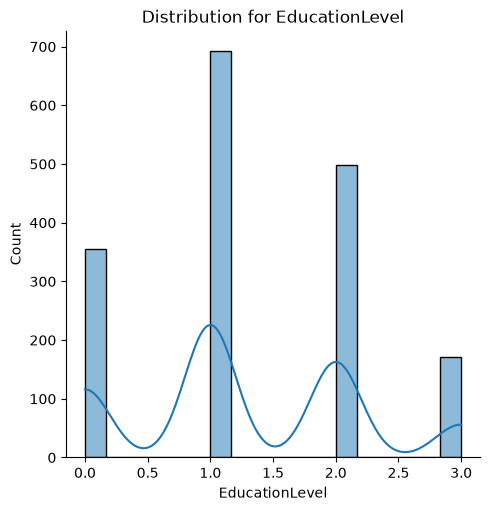

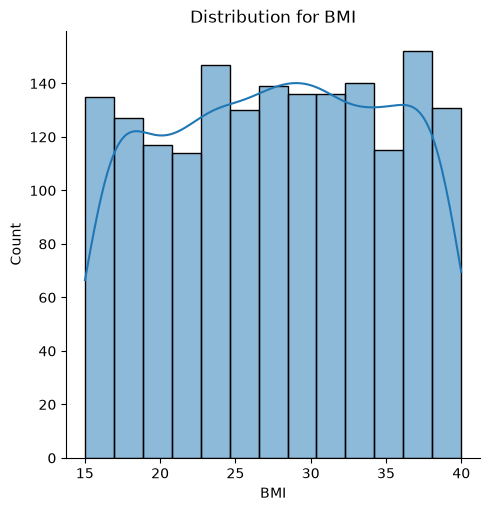

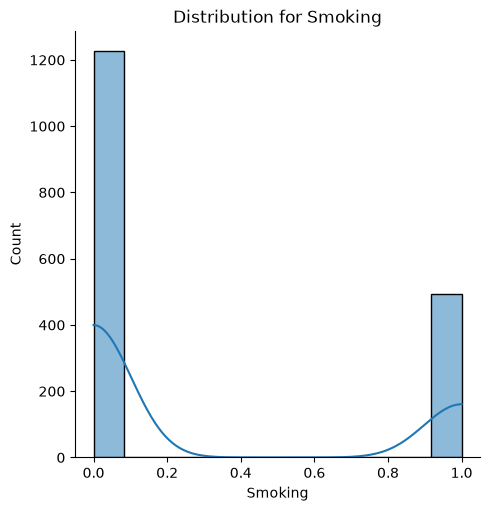

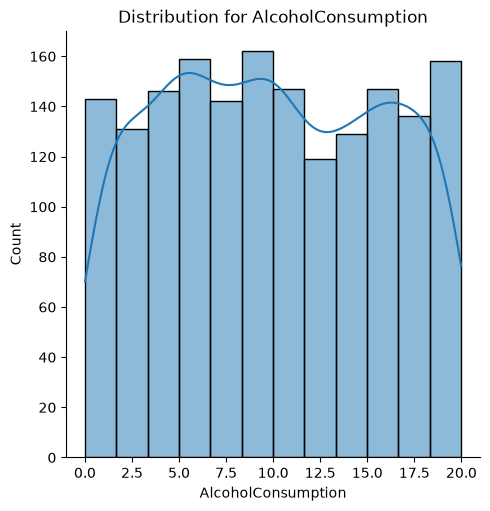

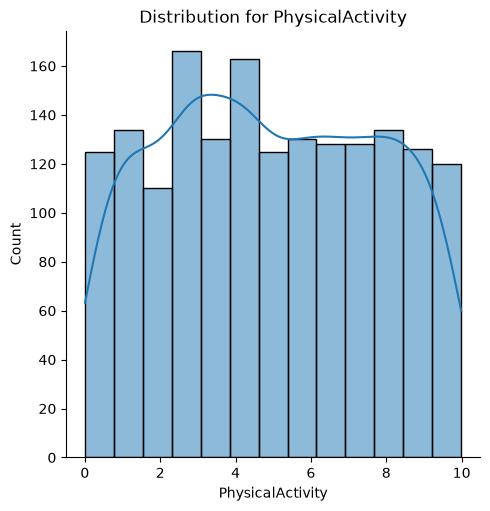

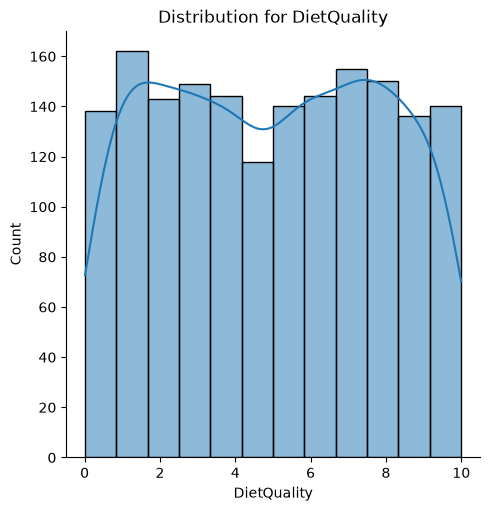

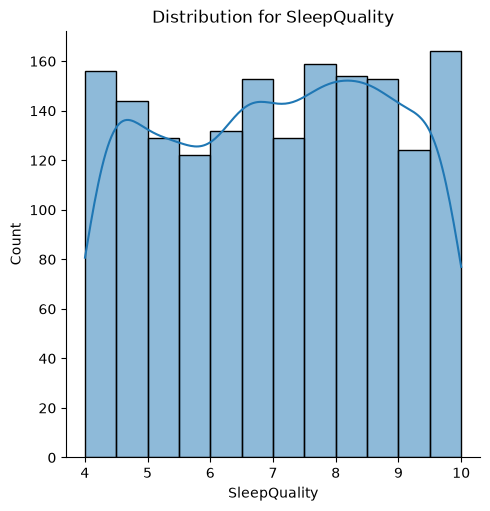

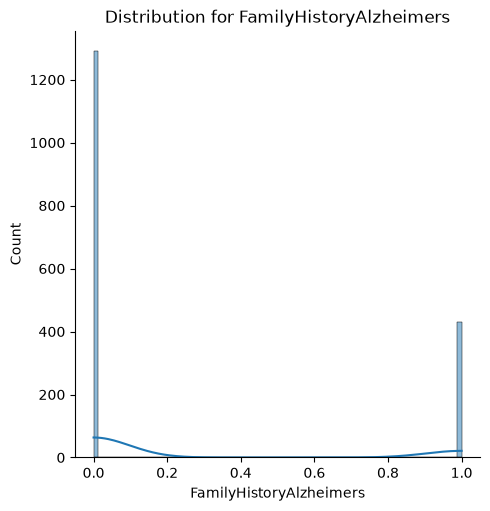

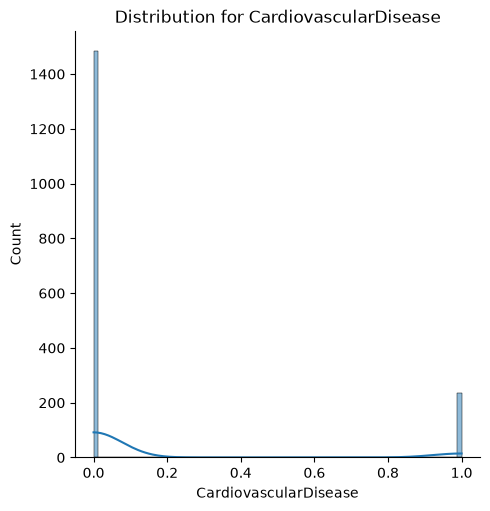

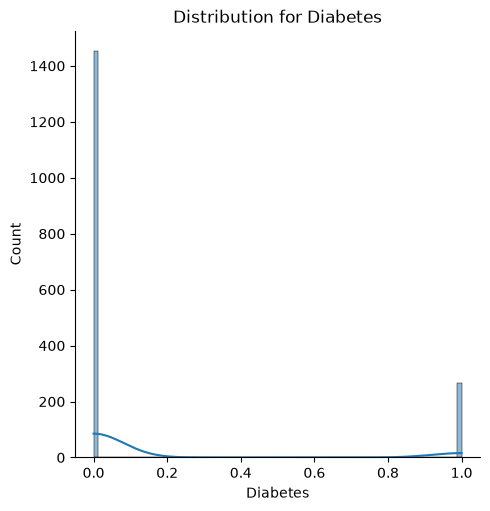

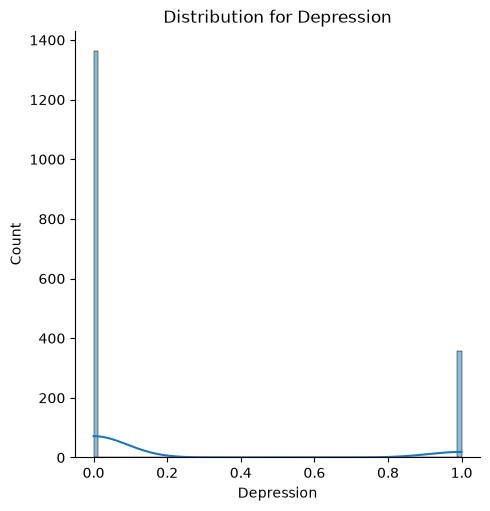

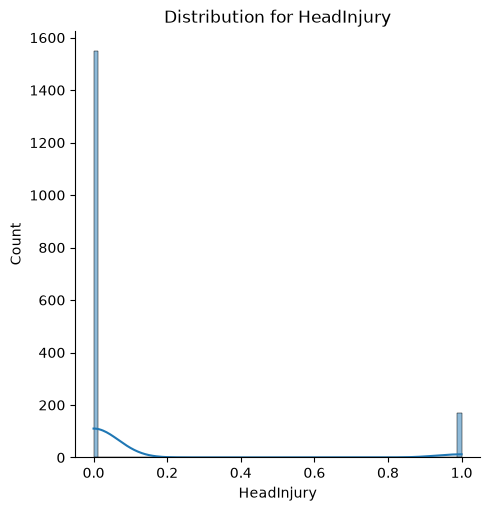

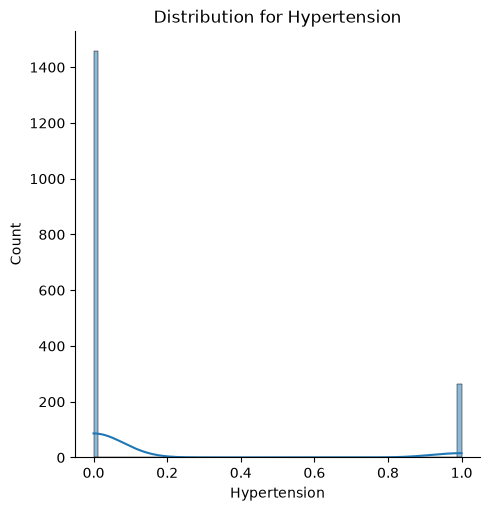

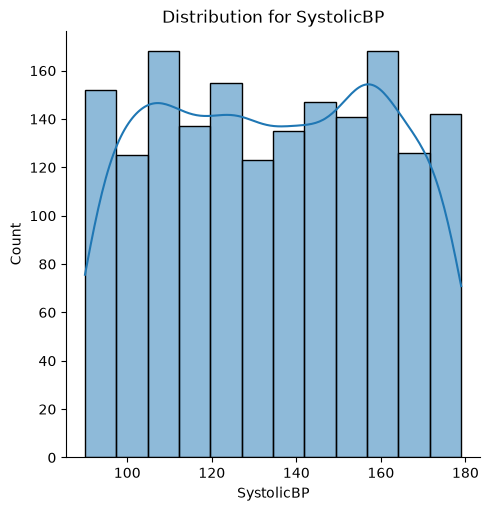

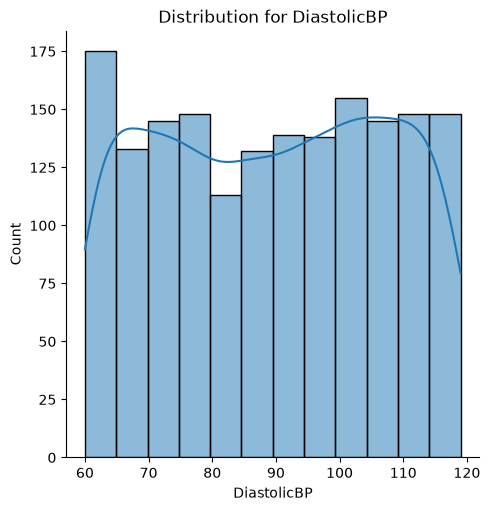

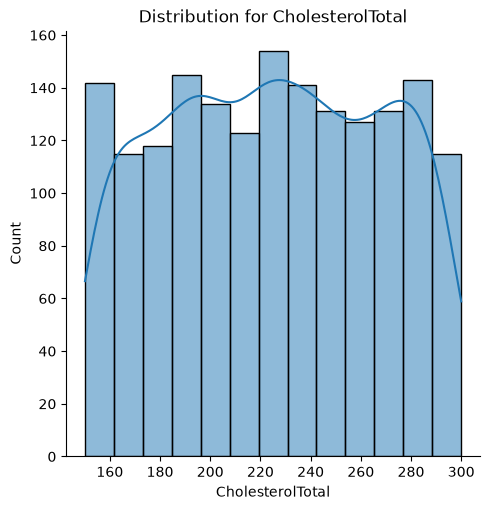

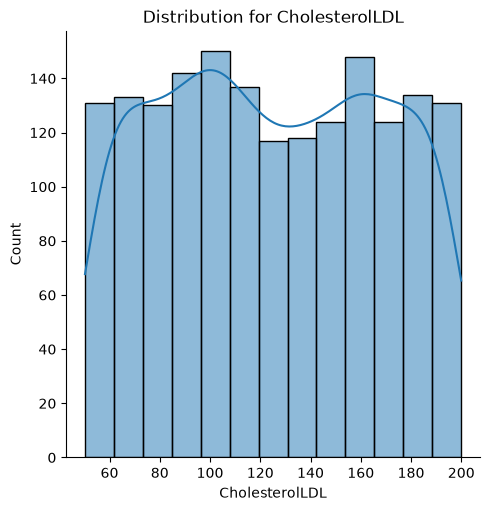

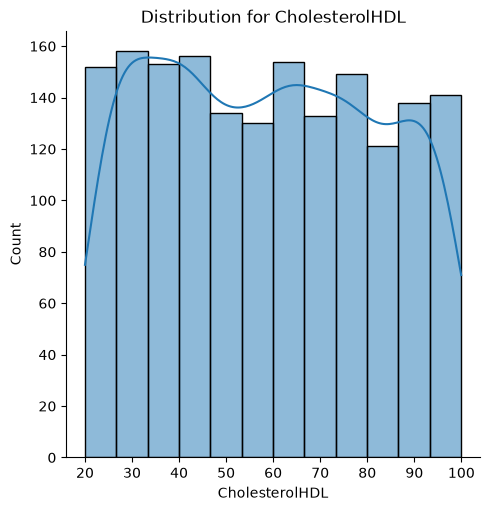

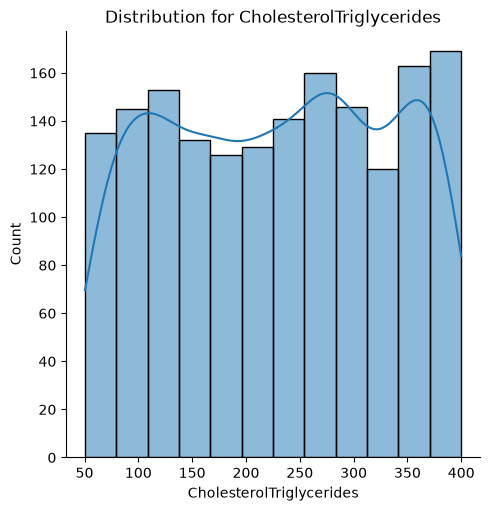

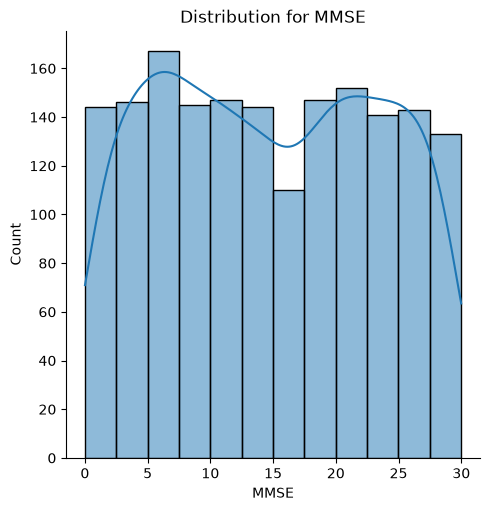

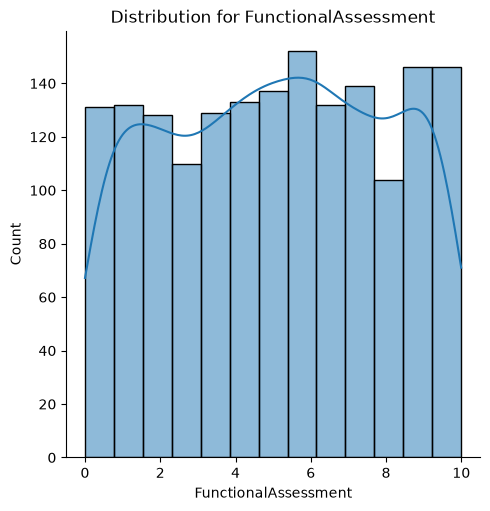

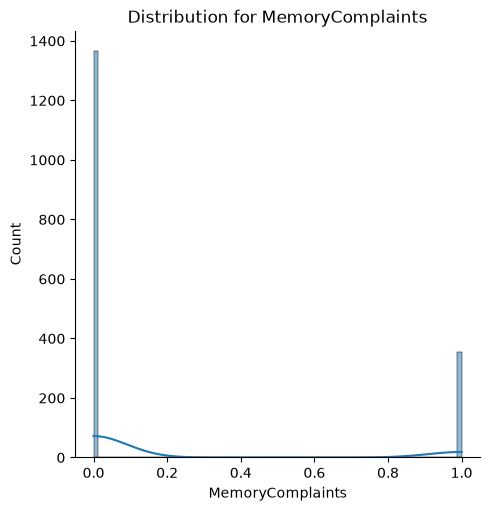

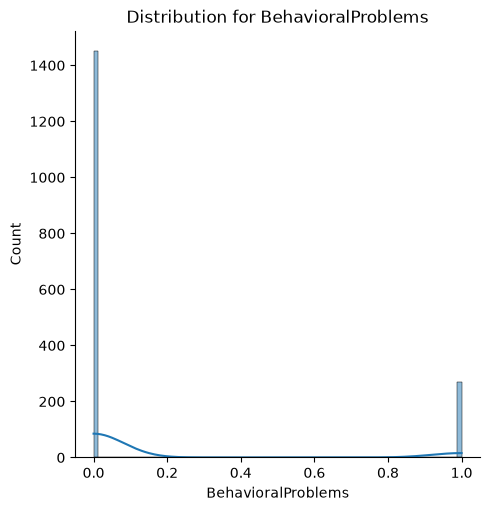

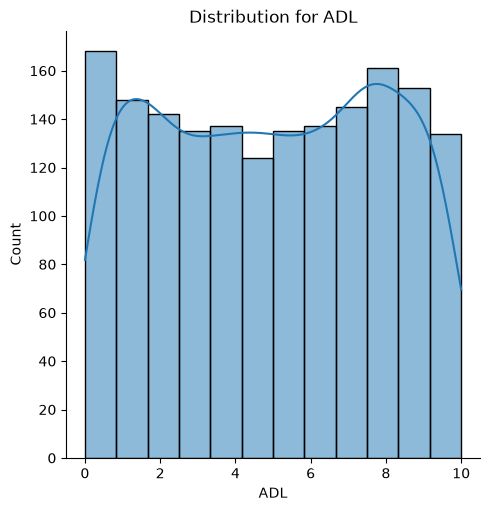

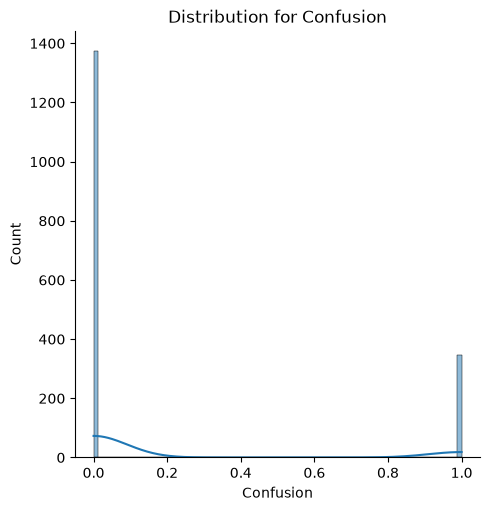

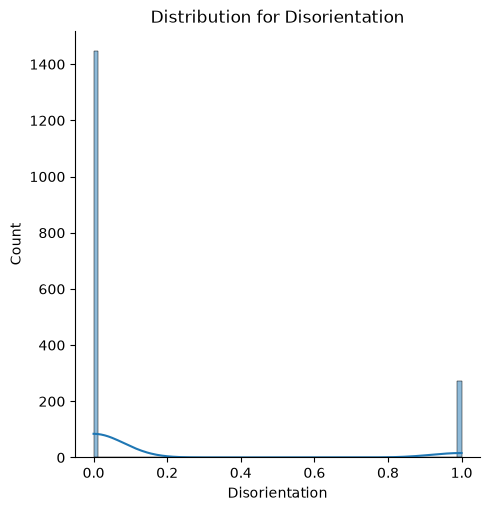

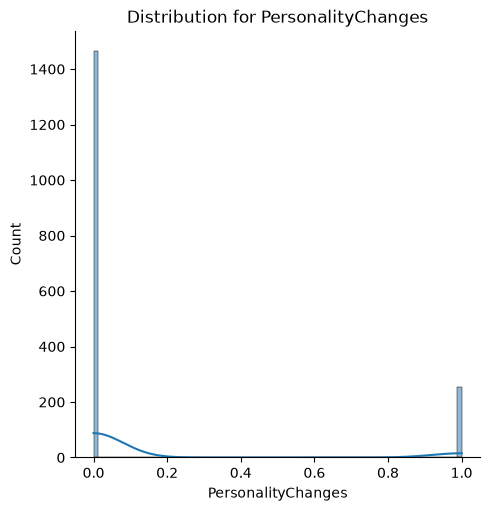

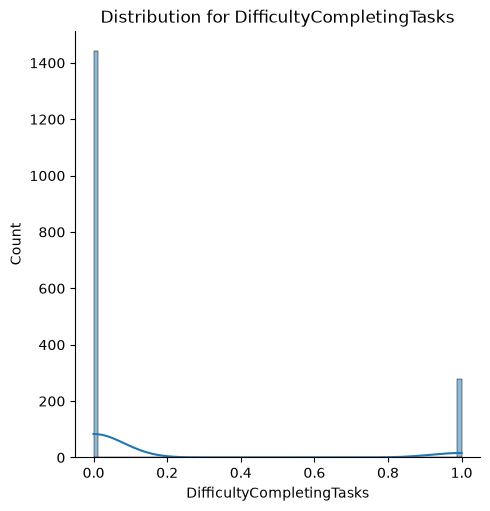

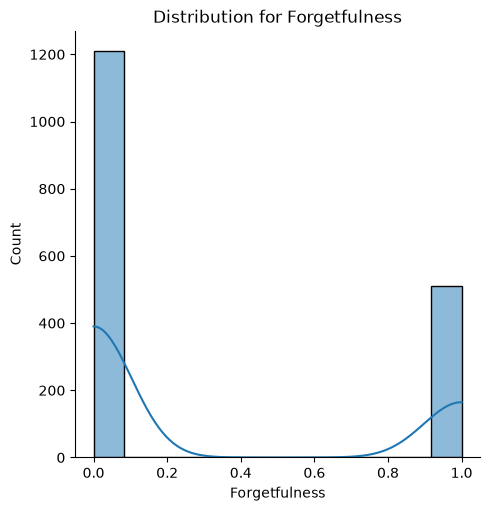

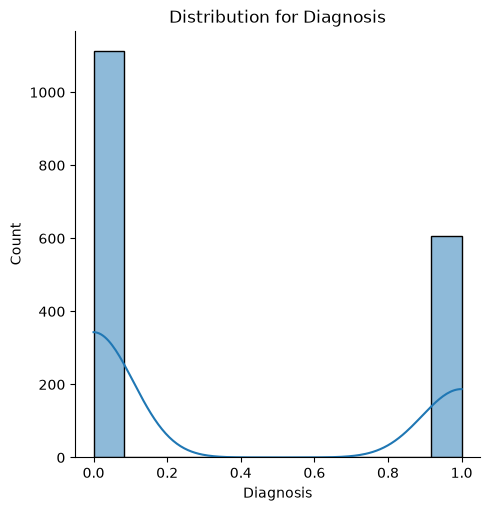

In [17]:
for column in  ['Age', 'Gender', 'Ethnicity', 'EducationLevel', 'BMI',
       'Smoking', 'AlcoholConsumption', 'PhysicalActivity', 'DietQuality',
       'SleepQuality', 'FamilyHistoryAlzheimers', 'CardiovascularDisease',
       'Diabetes', 'Depression', 'HeadInjury', 'Hypertension', 'SystolicBP',
       'DiastolicBP', 'CholesterolTotal', 'CholesterolLDL', 'CholesterolHDL',
       'CholesterolTriglycerides', 'MMSE', 'FunctionalAssessment',
       'MemoryComplaints', 'BehavioralProblems', 'ADL', 'Confusion',
       'Disorientation', 'PersonalityChanges', 'DifficultyCompletingTasks',
       'Forgetfulness', 'Diagnosis']:
    
    sns.displot(data=df, x=column, kde=True)
    plt.title(f"Distribution for {column}")
    plt.show()

It's interesting to see that, overall, binary variables, except for Gender, are imbalanced.

Our goal in this research is:  `Modelos treinados baseandose, somente, em dados de estilo de vida e testes clínicos conseguem assertividade equiparada à modelos dotados de maiores informações sobre o paciente?`. This way, let's focus on lifestyles and clinical tests by now

In [18]:
!cat "$path/data_description.txt"

About Dataset
This dataset contains extensive health information for 2,149 patients, each uniquely identified. The dataset includes demographic details, lifestyle factors, medical history, clinical measurements, cognitive and functional assessments, symptoms, and a diagnosis of Alzheimer's Disease. The data is ideal for researchers and data scientists looking to explore factors associated with Alzheimer's, develop predictive models, and conduct statistical analyses.

Table of Contents
Demographic Details
Lifestyle Factors
Medical History
Clinical Measurements
Cognitive and Functional Assessments
Symptoms
Diagnosis Information

Demographic Details
Age: The age of the patients ranges from 60 to 90 years.
Gender: Gender of the patients, where 0 represents Male and 1 represents Female.
Ethnicity: The ethnicity of the patients, coded as follows:
0: Caucasian
1: African American
2: Asian
3: Other

Lifestyle Factors
BMI: Body Mass Index of the patients, ranging from 15 to 40.
Smoking: Smoking

In [20]:
lifestyle_factors = ["BMI", "Smoking", "AlcoholConsumption","PhysicalActivity","DietQuality","SleepQuality"]

do_smoke = df.loc[df["Smoking"] == 1]
donot_smoke = df.loc[df["Smoking"] == 0]

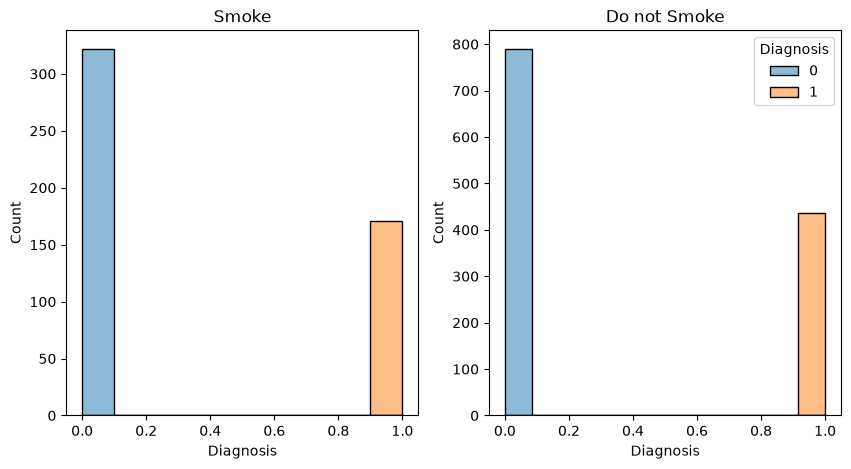

In [30]:
fig,ax = plt.subplots(1,2,figsize=(10,5))

sns.histplot(data=do_smoke, x="Diagnosis", hue="Diagnosis", ax=ax[0],legend=False)
sns.histplot(data=donot_smoke, x="Diagnosis", hue="Diagnosis", ax=ax[1], )

ax[0].set_title("Smoke")
ax[1].set_title("Do not Smoke")
plt.show()

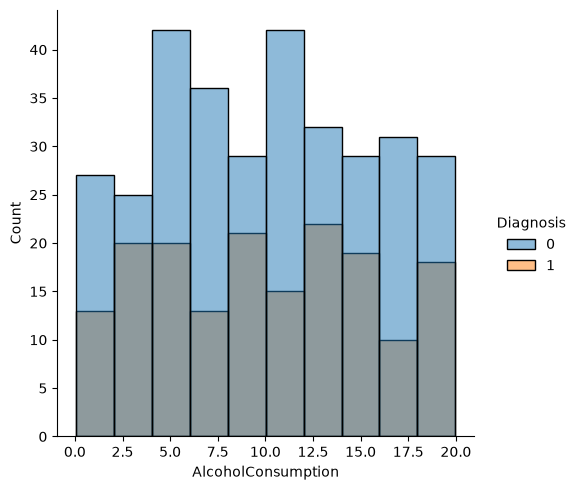

In [31]:
sns.displot(data=do_smoke, x="AlcoholConsumption", hue="Diagnosis")
plt.show()

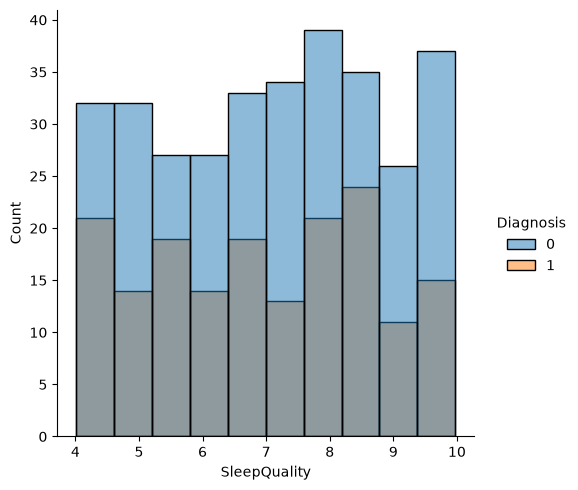

In [32]:
sns.displot(data=do_smoke, x="SleepQuality", hue="Diagnosis")
plt.show()

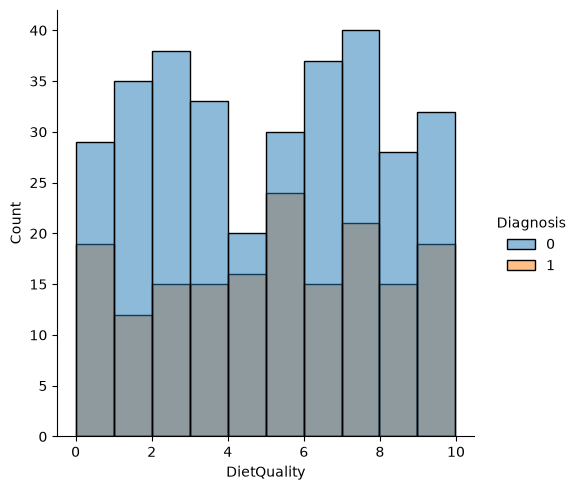

In [33]:
sns.displot(data=do_smoke, x="DietQuality", hue="Diagnosis")
plt.show()

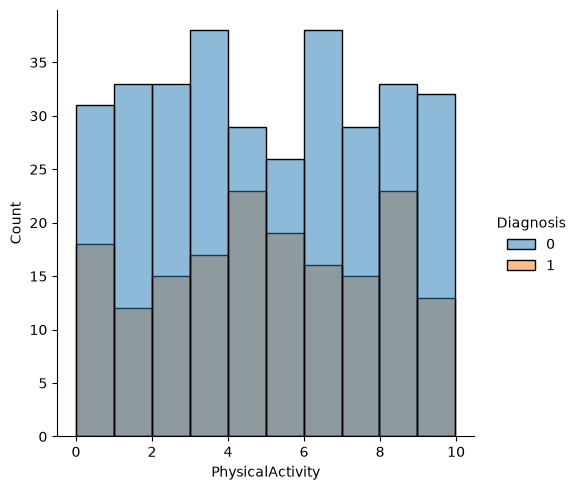

In [34]:
sns.displot(data=do_smoke, x="PhysicalActivity", hue="Diagnosis")
plt.show()

In [35]:
df["BMI_cat"] = "Underweight"
df.loc[(df["BMI"] >= 18.5)&(df["BMI"] < 25), "BMI_cat"] = "Normal"
df.loc[(df["BMI"] >= 25)&(df["BMI"] < 30), "BMI_cat"] = "Overweight"
df.loc[df["BMI"] >= 30, "BMI_cat"] = "Obese"

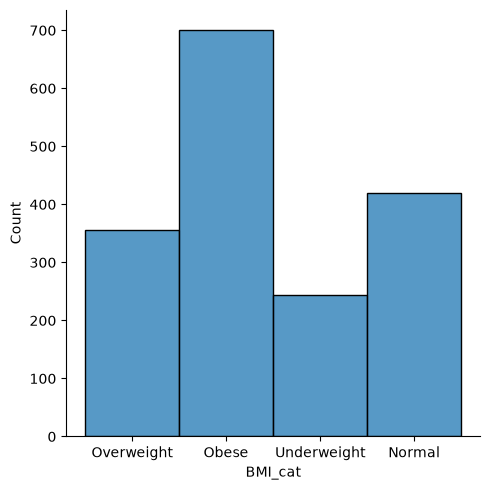

In [37]:
sns.displot(data=df, x="BMI_cat")
plt.show()

Most part of the people are obese. My idea is to join different combinations of factors in order to get some knowledge on groups. I'm going to join the data use PCA and try to find connections

In [40]:
df["health_points"] = 0
df.loc[df["Smoking"] == 0, "health_points"] += 1
df.loc[df["PhysicalActivity"] >= 2.5, "health_points"] += 1
df.loc[((df["AlcoholConsumption"]*8)/7 <= 15) & (df["Gender"] == 1), "health_points"] += 1 
df.loc[((df["AlcoholConsumption"]*8)/7 <= 30) & (df["Gender"] == 0), "health_points"] += 1
df.loc[df["SleepQuality"] >= 8, "health_points"] += 1
df.loc[df["DietQuality"] >= 8, "health_points"] += 1

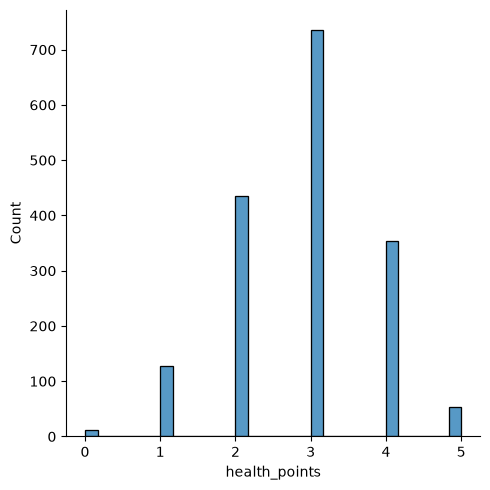

In [41]:
sns.displot(data=df, x="health_points")
plt.show()

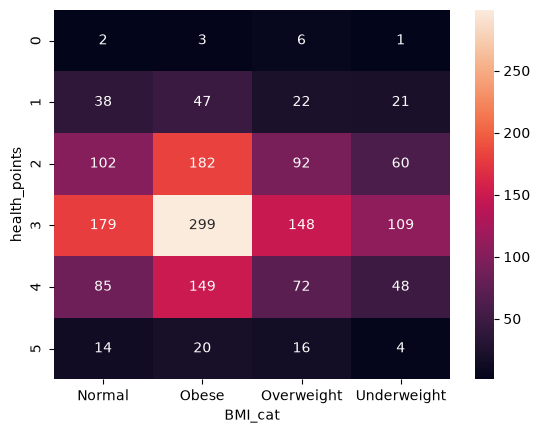

In [46]:
sns.heatmap(pd.crosstab(df.health_points, df.BMI_cat), annot=True, fmt=".0f")
plt.show()

In [48]:
df["cholesterol"] = df["CholesterolTotal"]/38.67
# Cholesterol is divided by 38.67 to convert from mm/dL to mmol/L https://heartcare.sydney/cholesterol-unit-conversion/

df["secondary_indicator"] = 2
df.loc[(df["SystolicBP"] <= 120) & (df["DiastolicBP"] <= 80) & (df["cholesterol"] < 5.18) & (df["Smoking"] == 0) & (df["Diabetes"] == 0), "secondary_indicator"] = 3
df.loc[(df["SystolicBP"] >= 140) | (df["DiastolicBP"] >= 90) | (df["cholesterol"] >= 6.22) | (df["Diabetes"] == 1) | (df["Smoking"] == 1), "secondary_indicator"] = 1

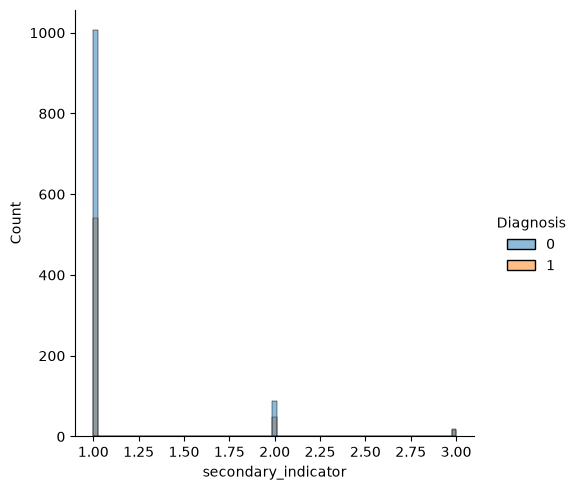

In [50]:
sns.displot(data=df,x="secondary_indicator", hue="Diagnosis")
plt.show()

In [51]:
df["T/HDL"] = df["CholesterolTriglycerides"]/df["CholesterolHDL"]

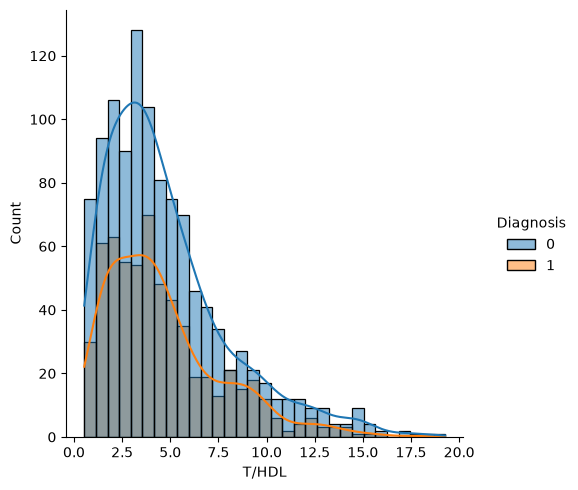

In [53]:
sns.displot(data=df,x="T/HDL", hue="Diagnosis", kde=True)
plt.show()

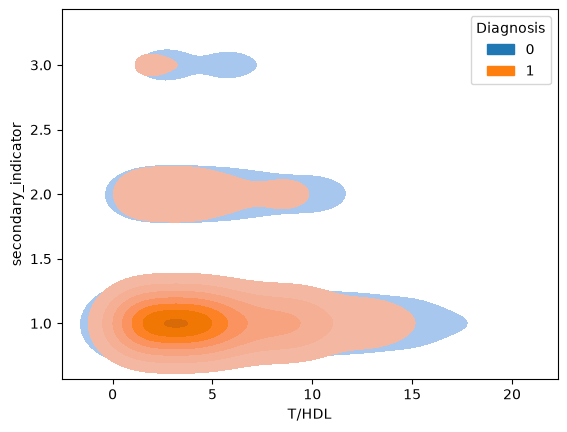

In [57]:
sns.kdeplot(data=df, x="T/HDL", y="secondary_indicator", hue="Diagnosis", fill=True)
plt.show()

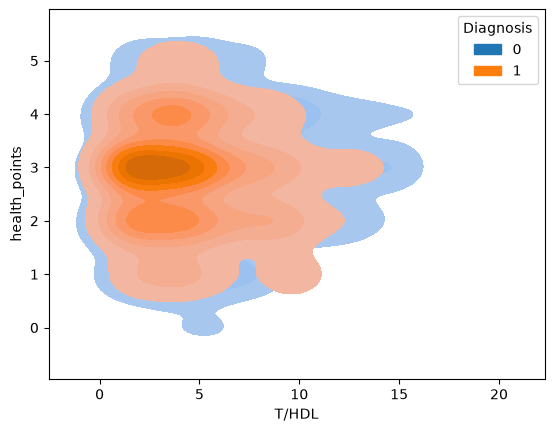

In [58]:
sns.kdeplot(data=df, x="T/HDL", y="health_points", hue="Diagnosis", fill=True)
plt.show()

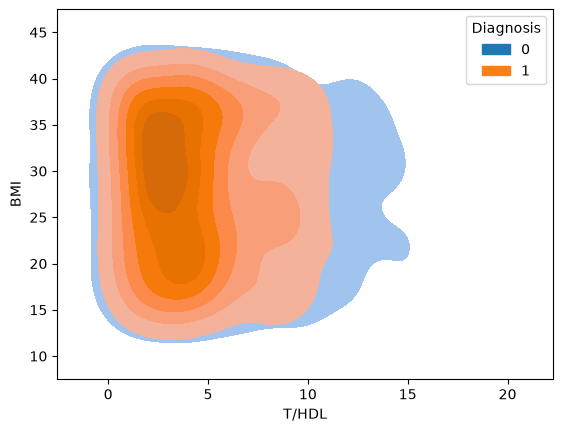

In [59]:
sns.kdeplot(data=df, x="T/HDL", y="BMI", hue="Diagnosis", fill=True)
plt.show()

Ok, we are sure to use these guys in the main model

Now we just need to ensure that neither data leakage nor overfit will occour in the other models. Since binary variables are pointing towards an specific point, it's a good 
idea to make data augmentation, which will do. 

Additionally, it would be nice to mine patterns in other to have four models:

1. the main model based on these medical tests
2. a model with raw variables
3. a model without data augmentation
4. a model with mined patterns from raw variables

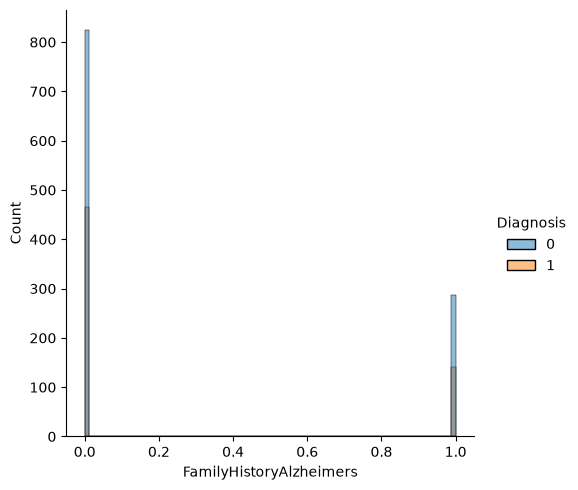

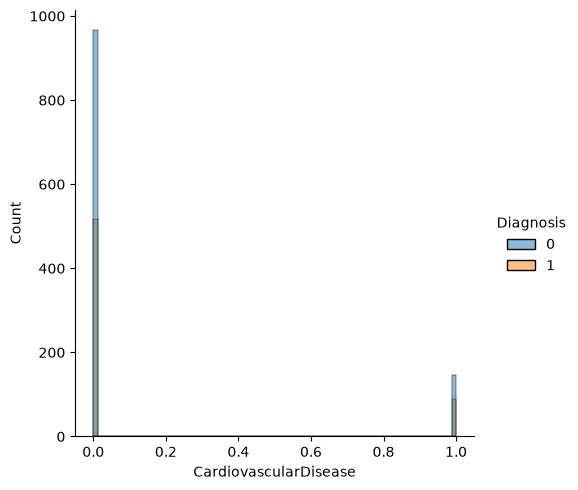

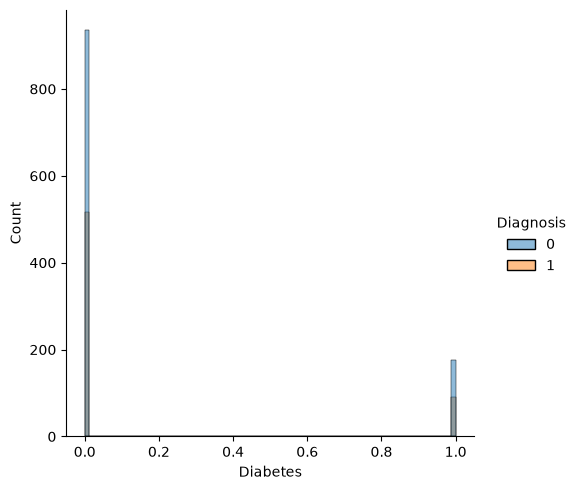

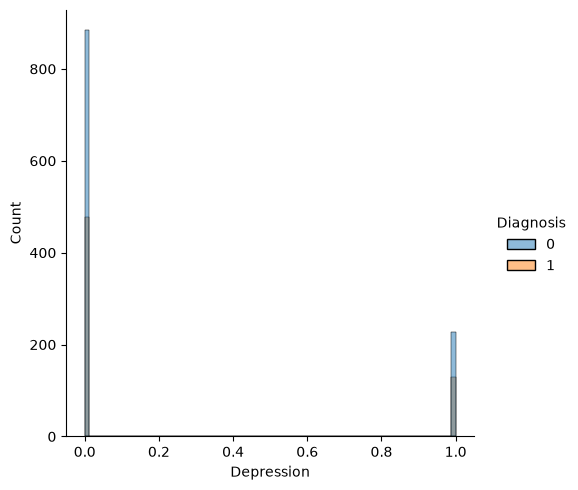

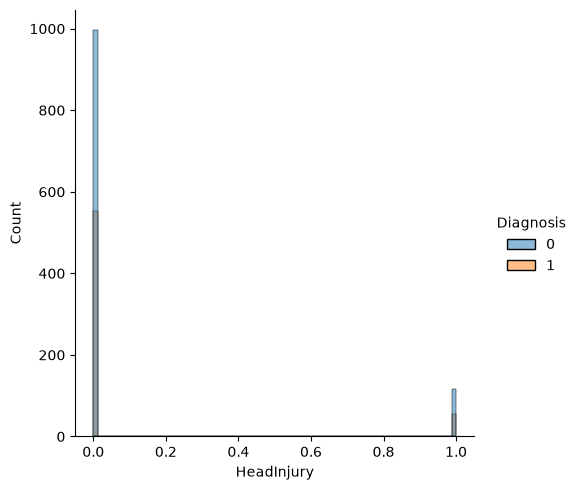

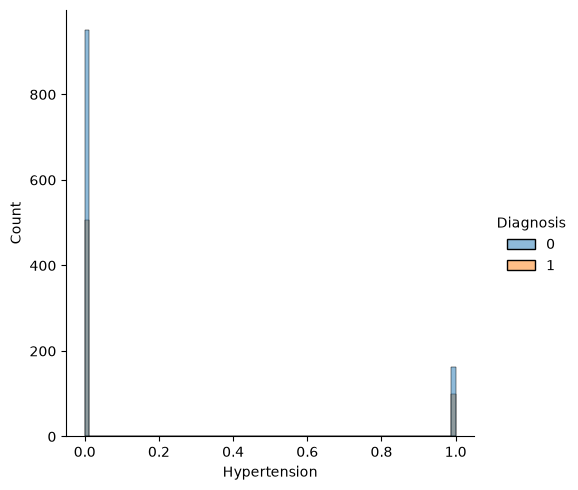

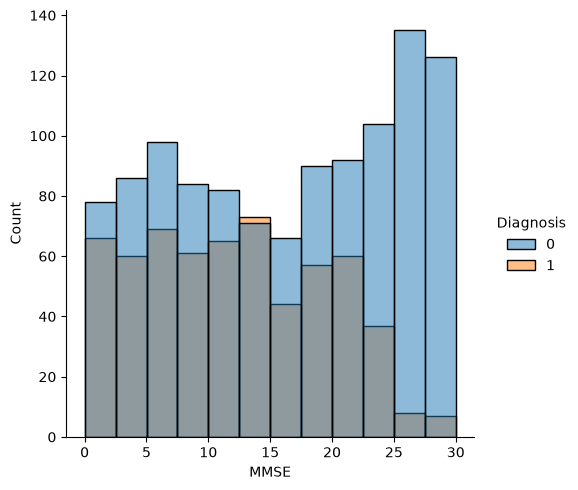

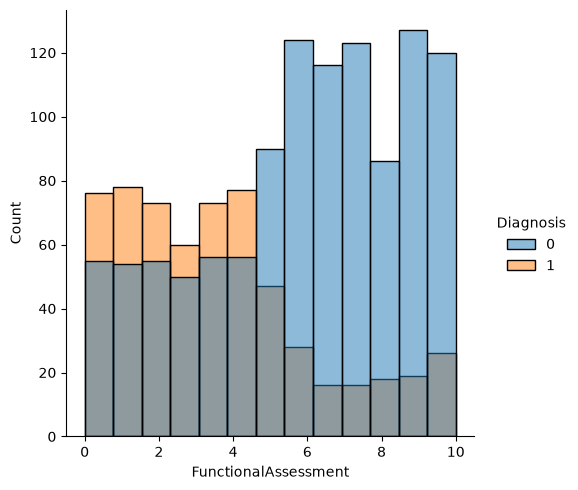

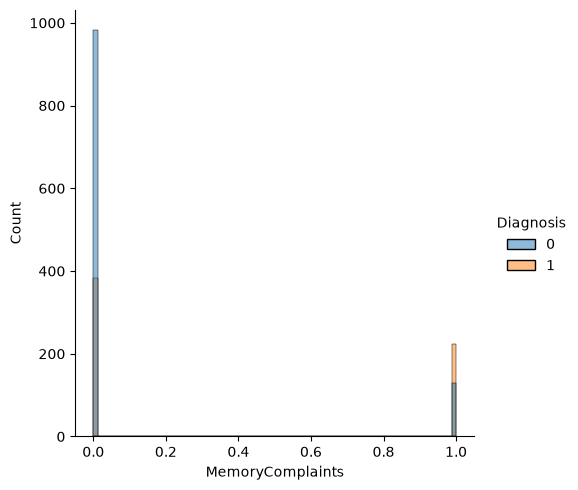

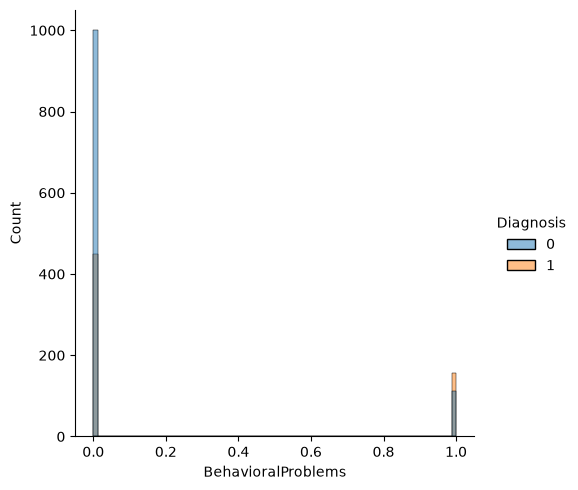

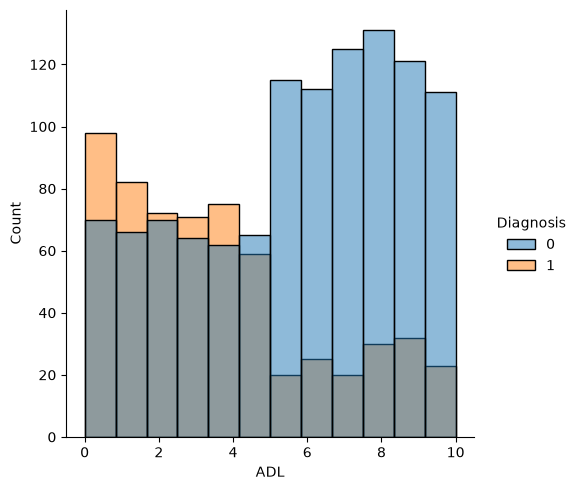

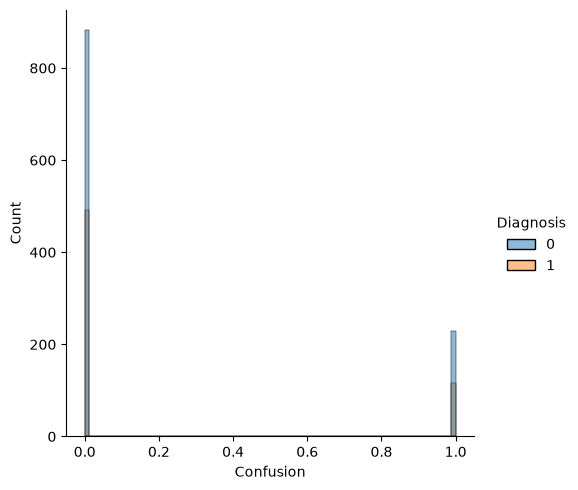

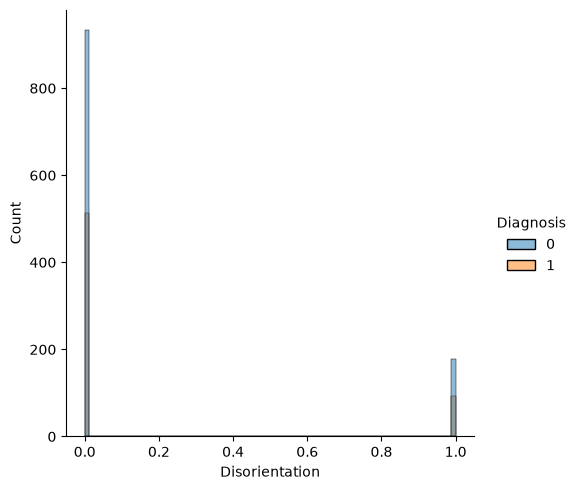

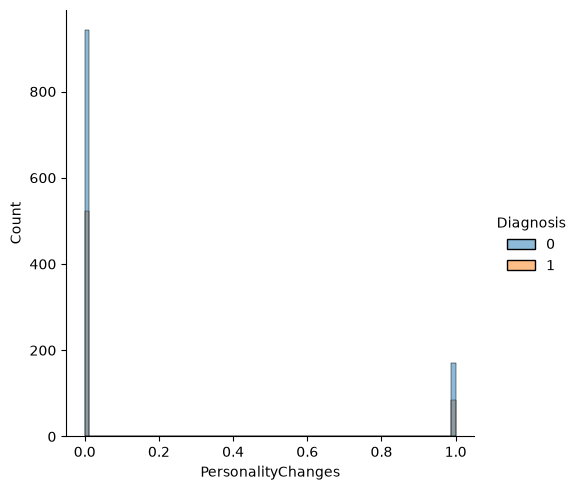

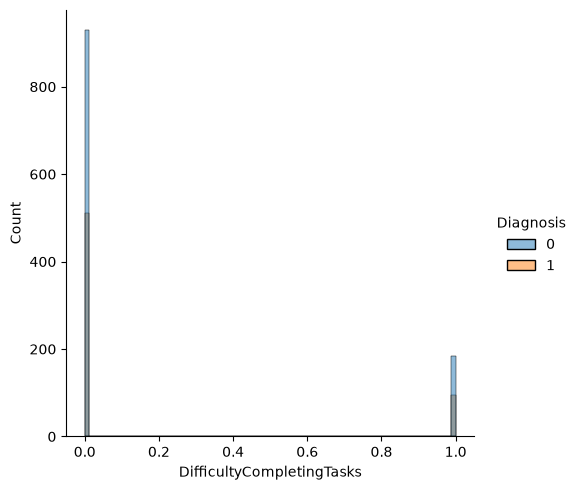

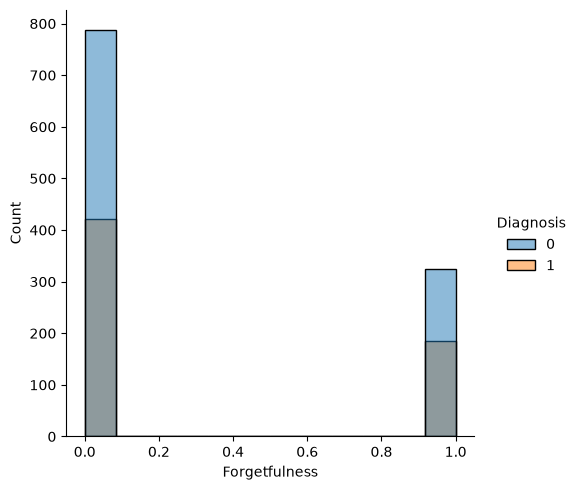

In [61]:
for i in ['FamilyHistoryAlzheimers', 'CardiovascularDisease',
       'Diabetes', 'Depression', 'HeadInjury', 'Hypertension', 'MMSE', 'FunctionalAssessment',
       'MemoryComplaints', 'BehavioralProblems', 'ADL', 'Confusion',
       'Disorientation', 'PersonalityChanges', 'DifficultyCompletingTasks',
       'Forgetfulness']:
    sns.displot(data=df, x=i, hue="Diagnosis")
    plt.show()

Actually, it seems like it's not a directly problem. We can use this by adding some augmentation. Instead, it is a good idea to test performance as we add different groups of columns.

So pretty much that's the project:

1. the main model based on these medical tests
2. a model with raw variables\
    2.1. evaluate as we add groups of variables
3. a model without data augmentation